# Heart Disease Prediction - Machine Learning Project

## 1. Setup & Data Loading
In this section, we import the necessary libraries for data manipulation, visualization, and machine learning, then load the dataset (`heart_2020_cleaned.csv`) to inspect its structure, dimensions, and data types.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('../data/heart_2020_cleaned.csv')

print(df.shape)
df.head()

(319795, 18)


,HeartDisease,BMI,Smoking,AlcoholDrinking,Stroke,PhysicalHealth,MentalHealth,DiffWalking,Sex,AgeCategory,Race,Diabetic,PhysicalActivity,GenHealth,SleepTime,Asthma,KidneyDisease,SkinCancer
0,No,16.60,Yes,No,No,3.0,30.0,No,Female,55-59,White,Yes,Yes,Very good,5.0,Yes,No,Yes
1,No,20.34,No,No,Yes,0.0,0.0,No,Female,80 or older,White,No,Yes,Very good,7.0,No,No,No
2,No,26.58,Yes,No,No,20.0,30.0,No,Male,65-69,White,Yes,Yes,Fair,8.0,Yes,No,No
3,No,24.21,No,No,No,0.0,0.0,No,Female,75-79,White,No,No,Good,6.0,No,No,Yes
4,No,23.71,No,No,No,28.0,0.0,Yes,Female,40-44,White,No,Yes,Very good,8.0,No,No,No


## 2. Data Cleaning & Preprocessing

In [3]:
df.shape

(319795, 18)

In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 319795 entries, 0 to 319794
Data columns (total 18 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   HeartDisease      319795 non-null  str    
 1   BMI               319795 non-null  float64
 2   Smoking           319795 non-null  str    
 3   AlcoholDrinking   319795 non-null  str    
 4   Stroke            319795 non-null  str    
 5   PhysicalHealth    319795 non-null  float64
 6   MentalHealth      319795 non-null  float64
 7   DiffWalking       319795 non-null  str    
 8   Sex               319795 non-null  str    
 9   AgeCategory       319795 non-null  str    
 10  Race              319795 non-null  str    
 11  Diabetic          319795 non-null  str    
 12  PhysicalActivity  319795 non-null  str    
 13  GenHealth         319795 non-null  str    
 14  SleepTime         319795 non-null  float64
 15  Asthma            319795 non-null  str    
 16  KidneyDisease     319795 non-nu

In [4]:
df.isnull().sum()

HeartDisease        0
BMI                 0
Smoking             0
AlcoholDrinking     0
Stroke              0
PhysicalHealth      0
MentalHealth        0
DiffWalking         0
Sex                 0
AgeCategory         0
Race                0
Diabetic            0
PhysicalActivity    0
GenHealth           0
SleepTime           0
Asthma              0
KidneyDisease       0
SkinCancer          0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(18078)

In [7]:
df.describe()

,BMI,PhysicalHealth,MentalHealth,SleepTime
count,319795.000000,319795.00000,319795.000000,319795.000000
mean,28.325399,3.37171,3.898366,7.097075
std,6.356100,7.95085,7.955235,1.436007
min,12.020000,0.00000,0.000000,1.000000
25%,24.030000,0.00000,0.000000,6.000000
50%,27.340000,0.00000,0.000000,7.000000
75%,31.420000,2.00000,3.000000,8.000000
max,94.850000,30.00000,30.000000,24.000000


In [8]:
df.drop_duplicates(inplace=True)

C:\Users\moham\AppData\Local\Temp\ipykernel_15588\3006716147.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)


In [9]:
df.shape

(301717, 18)

## 3. Exploratory Data Analysis (EDA)

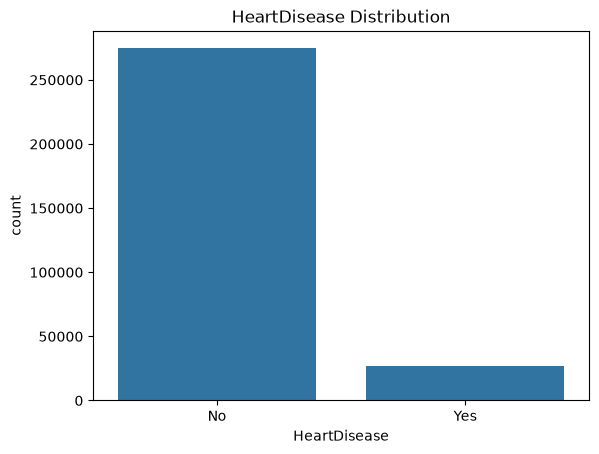

In [10]:
sns.countplot(x='HeartDisease', data=df)
plt.title('HeartDisease Distribution')
plt.show()

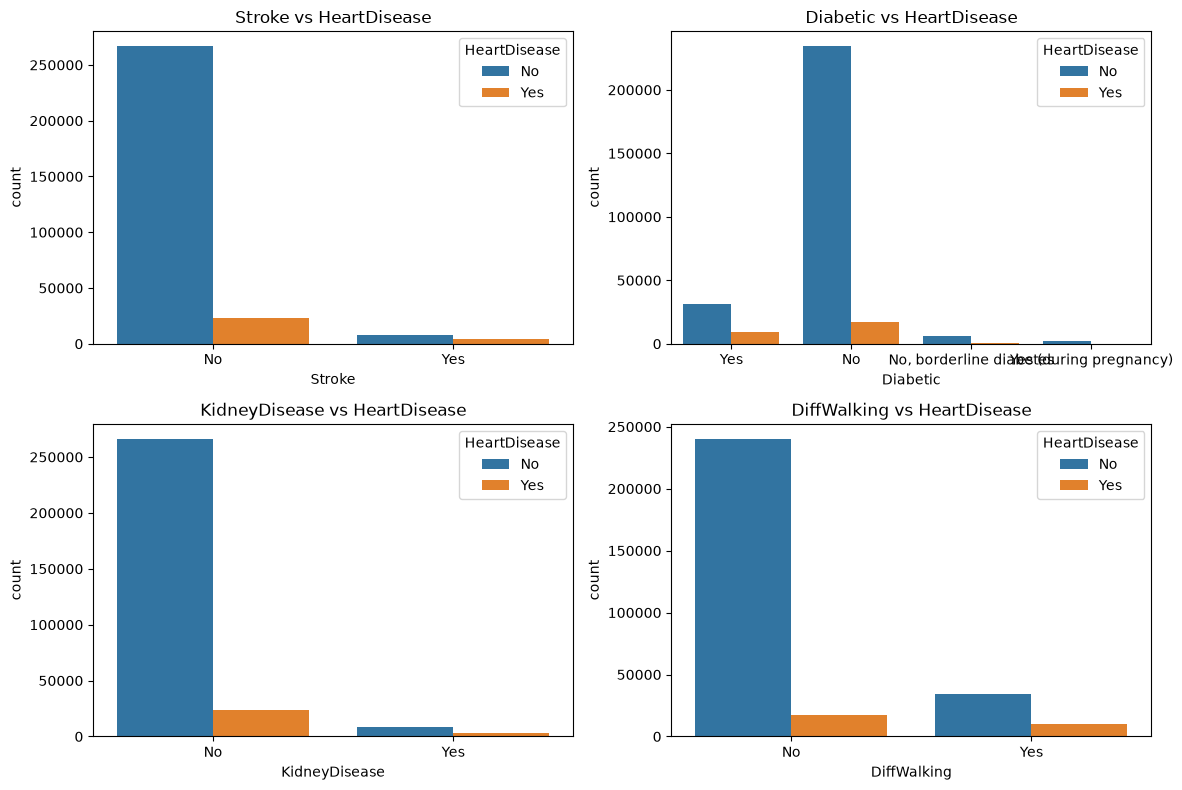

In [11]:
chronic_cols = ['Stroke', 'Diabetic', 'KidneyDisease', 'DiffWalking']
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for col, ax in zip(chronic_cols, axes.flatten()):
    sns.countplot(x=col, hue='HeartDisease', data=df, ax=ax)
    ax.set_title(f'{col} vs HeartDisease')
plt.tight_layout()
plt.show()

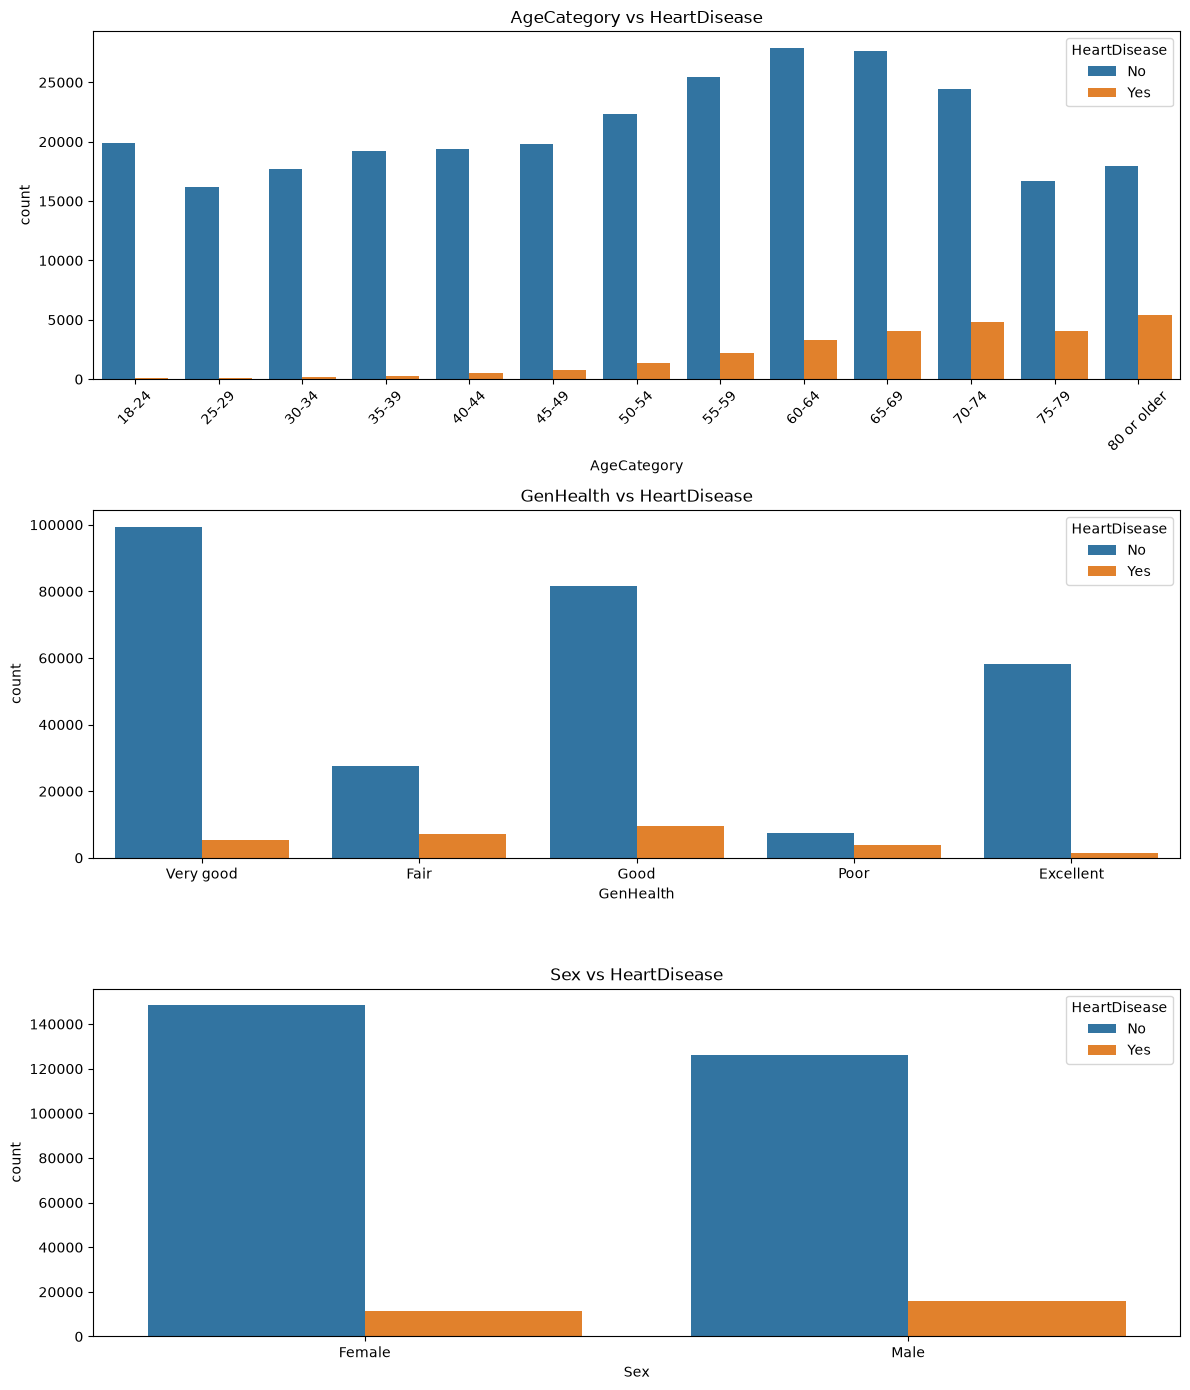

In [12]:
fig, axes = plt.subplots(3, 1, figsize=(12, 14))
sns.countplot(x='AgeCategory', hue='HeartDisease', data=df, order=sorted(df['AgeCategory'].unique()), ax=axes[0])
axes[0].set_title('AgeCategory vs HeartDisease')
axes[0].tick_params(axis='x', rotation=45)

sns.countplot(x='GenHealth', hue='HeartDisease', data=df, ax=axes[1])
axes[1].set_title('GenHealth vs HeartDisease')

sns.countplot(x='Sex', hue='HeartDisease', data=df, ax=axes[2])
axes[2].set_title('Sex vs HeartDisease')

plt.tight_layout()
plt.show()

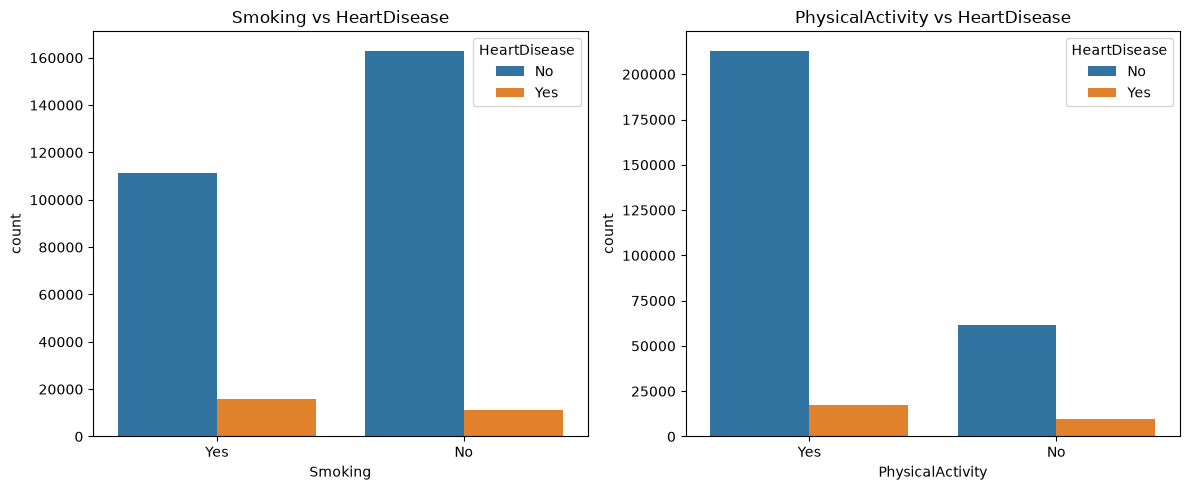

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
sns.countplot(x='Smoking', hue='HeartDisease', data=df, ax=axes[0])
axes[0].set_title('Smoking vs HeartDisease')

sns.countplot(x='PhysicalActivity', hue='HeartDisease', data=df, ax=axes[1])
axes[1].set_title('PhysicalActivity vs HeartDisease')

plt.tight_layout()
plt.show()

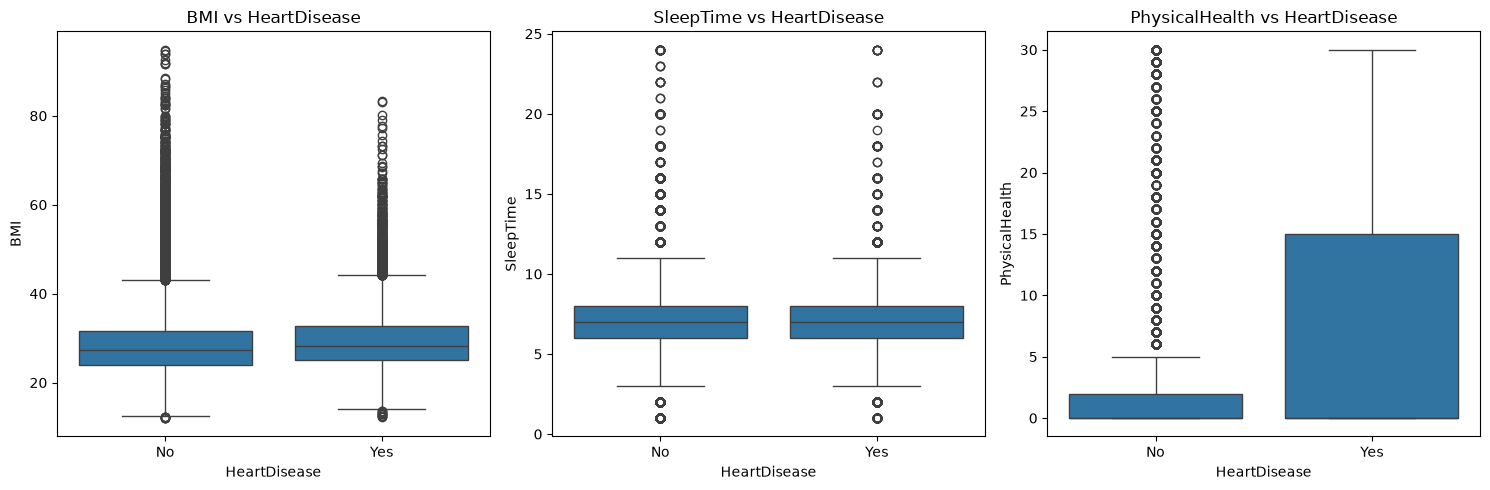

In [14]:
num_cols = ['BMI', 'SleepTime', 'PhysicalHealth']
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for col, ax in zip(num_cols, axes):
    sns.boxplot(x='HeartDisease', y=col, data=df, ax=ax)
    ax.set_title(f'{col} vs HeartDisease')
plt.tight_layout()
plt.show()

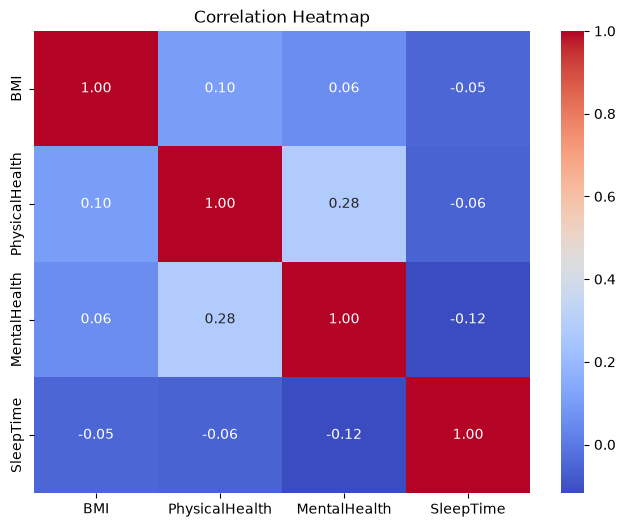

In [15]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[['BMI', 'PhysicalHealth', 'MentalHealth', 'SleepTime']].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Heatmap')
plt.show()

## 4. Data Preprocessing

In [16]:
df_ml = df.copy()

# Binary columns
binary_cols = ['HeartDisease', 'Smoking', 'AlcoholDrinking', 'Stroke', 
               'DiffWalking', 'PhysicalActivity', 'Asthma', 'KidneyDisease', 'SkinCancer']
for col in binary_cols:
    df_ml[col] = df_ml[col].map({'Yes': 1, 'No': 0})

df_ml['Sex'] = df_ml['Sex'].map({'Male': 1, 'Female': 0})

# Ordinal columns
gen_health_map = {'Poor': 0, 'Fair': 1, 'Good': 2, 'Very good': 3, 'Excellent': 4}
df_ml['GenHealth'] = df_ml['GenHealth'].map(gen_health_map)

age_map = {
    '18-24': 0, '25-29': 1, '30-34': 2, '35-39': 3, '40-44': 4,
    '45-49': 5, '50-54': 6, '55-59': 7, '60-64': 8, '65-69': 9,
    '70-74': 10, '75-79': 11, '80 or older': 12
}
df_ml['AgeCategory'] = df_ml['AgeCategory'].map(age_map)

# One-Hot Encoding for nominal columns
df_ml = pd.get_dummies(df_ml, columns=['Race', 'Diabetic'], drop_first=True)
df_ml.head()

,HeartDisease,BMI,Smoking,AlcoholDrinking,Stroke,PhysicalHealth,MentalHealth,DiffWalking,Sex,AgeCategory,...,KidneyDisease,SkinCancer,Race_Asian,Race_Black,Race_Hispanic,Race_Other,Race_White,"Diabetic_No, borderline diabetes",Diabetic_Yes,Diabetic_Yes (during pregnancy)
0,0,16.60,1,0,0,3.0,30.0,0,0,7,...,0,1,False,False,False,False,True,False,True,False
1,0,20.34,0,0,1,0.0,0.0,0,0,12,...,0,0,False,False,False,False,True,False,False,False
2,0,26.58,1,0,0,20.0,30.0,0,1,9,...,0,0,False,False,False,False,True,False,True,False
3,0,24.21,0,0,0,0.0,0.0,0,0,11,...,0,1,False,False,False,False,True,False,False,False
4,0,23.71,0,0,0,28.0,0.0,1,0,4,...,0,0,False,False,False,False,True,False,False,False


In [17]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import RobustScaler

X = df_ml.drop('HeartDisease', axis=1)
y = df_ml['HeartDisease']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

num_cols = ['BMI', 'PhysicalHealth', 'MentalHealth', 'SleepTime']
scaler = RobustScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test[num_cols] = scaler.transform(X_test[num_cols])

print(f"Train shape: {X_train.shape}, Test shape: {X_test.shape}")

Train shape: (241373, 23), Test shape: (60344, 23)


## 5. Model Training & Evaluation

Logistic Regression ROC-AUC: 0.8324

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.74      0.84     54892
           1       0.23      0.77      0.35      5452

    accuracy                           0.74     60344
   macro avg       0.60      0.75      0.60     60344
weighted avg       0.90      0.74      0.80     60344



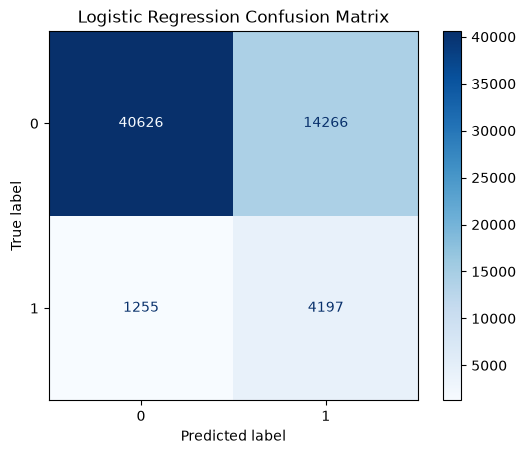

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, ConfusionMatrixDisplay

lr_model = LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)
y_prob_lr = lr_model.predict_proba(X_test)[:, 1]

print("Logistic Regression ROC-AUC:", round(roc_auc_score(y_test, y_prob_lr), 4))
print("\nClassification Report:\n", classification_report(y_test, y_pred_lr))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_lr, cmap='Blues')
plt.title('Logistic Regression Confusion Matrix')
plt.show()

Random Forest ROC-AUC: 0.7886

Classification Report:
               precision    recall  f1-score   support

           0       0.93      0.92      0.93     54892
           1       0.30      0.32      0.31      5452

    accuracy                           0.87     60344
   macro avg       0.61      0.62      0.62     60344
weighted avg       0.87      0.87      0.87     60344



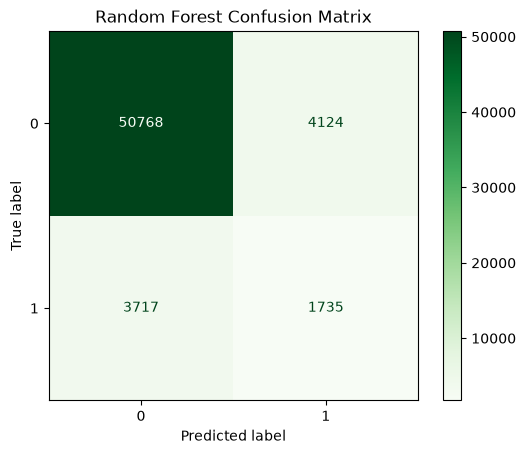

In [19]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(n_estimators=100, class_weight='balanced', n_jobs=-1, random_state=42)
rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)
y_prob_rf = rf_model.predict_proba(X_test)[:, 1]

print("Random Forest ROC-AUC:", round(roc_auc_score(y_test, y_prob_rf), 4))
print("\nClassification Report:\n", classification_report(y_test, y_pred_rf))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_rf, cmap='Greens')
plt.title('Random Forest Confusion Matrix')
plt.show()

## 6. Save Model & Scaler

In [20]:
import joblib

model_data = {
    'model': lr_model,
    'scaler': scaler,
    'columns': X_train.columns.tolist()
}

joblib.dump(model_data, '../models/heart_disease_model.pkl')
print("Model saved successfully!")

Model saved successfully!
